In [1]:
#cell 1
# CAPM & Security Market Line Analysis (Refined Methodology)

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# Analysis Settings here we go
TICKERS = [
    "AAPL", "MSFT", "NVDA", "JPM", "GS",
    "XOM", "KO", "WMT", "JNJ", "CAT"
]

# Market Benchmark: Use SPY (Total Return ETF) instead of ^GSPC (Price Index)
MARKET_TICKER = "SPY"

# Risk-Free Benchmark: 13-Week US Treasury Bill (^IRX)
RF_TICKER = "^IRX"

# Time Horizon
START_DATE = "2020-01-01"
END_DATE = "2025-01-01"

TRADING_DAYS = 252

# Theoretical/Forward-looking Equity Risk Premium (for SML theoretical benchmarks)
EXPECTED_ERP = 0.055  # 5.5% standard ERP

pd.set_option("display.float_format", "{:.4f}".format)

print("CAPM & SML Analysis (Refined)")
print(f"Number of stocks: {len(TICKERS)}")
print(f"Market benchmark: {MARKET_TICKER} (Total Return)")
print(f"Risk-free ticker: {RF_TICKER} (Dynamic 13-Week T-Bill)")
print(f"Analysis period:  {START_DATE} to {END_DATE}")


CAPM & SML Analysis (Refined)
Number of stocks: 10
Market benchmark: SPY (Total Return)
Risk-free ticker: ^IRX (Dynamic 13-Week T-Bill)
Analysis period:  2020-01-01 to 2025-01-01


In [3]:
#cell 2
# Download historical adjusted prices & Risk-Free Rate series

all_equity_tickers = TICKERS + [MARKET_TICKER]

# 1. خب قیمت های تعدیل شده رو دانلود کنیم
try:
    equity_data = yf.download(
        all_equity_tickers,
        start=START_DATE,
        end=END_DATE,
        auto_adjust=True,
        progress=False,
        multi_level_index=False
    )["Close"]
except TypeError:
    equity_data = yf.download(
        all_equity_tickers,
        start=START_DATE,
        end=END_DATE,
        auto_adjust=True,
        progress=False
    )["Close"]

#  مرتب‌سازی تاریخ و اعتبارسنجی سهام انجام شد
equity_data = equity_data.sort_index().dropna(how="all")
missing_tickers = [t for t in all_equity_tickers if t not in equity_data.columns or equity_data[t].isna().all()]
if missing_tickers:
    raise ValueError(f"Failed to download data for: {missing_tickers}")

#  ردیف‌های گم‌شده در سهام رو حذف کنیم
equity_data = equity_data.dropna()

# 2. دانلود نرخ بازده اسناد خزانه 13 هفته‌ای (^IRX)
try:
    rf_raw = yf.download(
        RF_TICKER,
        start=START_DATE,
        end=END_DATE,
        progress=False,
        multi_level_index=False
    )["Close"]
except TypeError:
    rf_raw = yf.download(
        RF_TICKER,
        start=START_DATE,
        end=END_DATE,
        progress=False
    )["Close"]

# اگر فرمت خروجی سری یا دیتافریم تک‌ستونه بود
if isinstance(rf_raw, pd.DataFrame):
    rf_series = rf_raw.iloc[:, 0]
else:
    rf_series = rf_raw

# تراز کردن نرخ بدون ریسک با تقویم معاملاتی سهام (پر کردن روزهای تعطیلی خاص اوراق قرضه با ffill)
rf_aligned = rf_series.reindex(equity_data.index).ffill().bfill()

# تبدیل نرخ سالانه درصدی (مثلاً 4.5) به نرخ روزانه هندسی
# ^IRX is in annual percentage points, so divide by 100 first
rf_annual_rate = rf_aligned / 100.0
daily_rf = (1 + rf_annual_rate) ** (1 / TRADING_DAYS) - 1
daily_rf.name = "Daily_Rf"

# میانگین موزون یا ساده نرخ بدون ریسک سالانه در کل دوره (برای بنچمارک‌های سالانه)
AVG_RISK_FREE_RATE = rf_annual_rate.mean()

print(f"Equity data shape: {equity_data.shape}")
print(f"Date range: {equity_data.index.min().date()} to {equity_data.index.max().date()}")
print(f"Average Annualized Risk-Free Rate (^IRX): {AVG_RISK_FREE_RATE:.2%}")
print(f"Missing values in equities: {equity_data.isna().sum().sum()}")

display(equity_data.head())

Equity data shape: (1258, 11)
Date range: 2020-01-02 to 2024-12-31
Average Annualized Risk-Free Rate (^IRX): 2.47%
Missing values in equities: 0


Ticker,AAPL,CAT,GS,JNJ,JPM,KO,MSFT,NVDA,SPY,WMT,XOM
Date,,,,,,,,,,,
2020-01-02,72.2715,132.0679,200.2513,121.3385,117.3139,44.8735,151.5443,5.9571,295.3918,36.2033,52.6064
2020-01-03,71.5689,130.2342,197.9097,119.9337,115.7658,44.6287,149.6573,5.8618,293.1551,35.8837,52.1835
2020-01-06,72.1392,130.1464,199.9351,119.7841,115.6738,44.6124,150.0441,5.8864,294.2734,35.8106,52.5841
2020-01-07,71.7999,128.4269,201.2512,120.5156,113.7073,44.2696,148.6760,5.9576,293.4459,35.4789,52.1538
2020-01-08,72.9549,129.5674,203.1911,120.4990,114.5943,44.3512,151.0442,5.9688,295.0099,35.3571,51.3673


In [5]:
#cell 3
# Calculate daily returns and systematic risk (Beta)

# 1. محاسبه بازده‌های روزانه کل سهام و بازار (SPY)
returns = equity_data.pct_change().dropna(how="any")

# همگام‌سازی سری زمانی نرخ بدون ریسک با تاریخ‌های بازده روزانه
daily_rf = daily_rf.loc[returns.index]

stock_returns = returns[TICKERS]
market_returns = returns[MARKET_TICKER]

# 2. محاسبه بازده‌های مازاد روزانه (Daily Excess Returns)
stock_excess = stock_returns.sub(daily_rf, axis=0)
market_excess = market_returns - daily_rf

market_excess_var = market_excess.var()

# 3. محاسبه بتای متدولوژیک (بر پایه بازده مازاد)
betas = stock_excess.apply(
    lambda stock: stock.cov(market_excess) / market_excess_var
)

beta_results = (
    betas.rename("Beta")
    .sort_values(ascending=False)
    .to_frame()
)

print(f"Daily observations: {len(returns)}")
print(f"Daily excess return sample size: {len(market_excess)}")
display(beta_results.round(4))


Daily observations: 1257
Daily excess return sample size: 1257


,Beta
Ticker,
NVDA,1.7855
AAPL,1.1930
MSFT,1.1898
GS,1.1600
JPM,1.0939
CAT,0.9705
XOM,0.8470
KO,0.6292
JNJ,0.4858


In [7]:
#cell 4
# CAPM expected returns and historical performance

# 1. بازده سالانه بازار و نرخ بدون ریسک بر مبنای داده‌های واقعی ^IRX
annualized_market_return = market_returns.mean() * TRADING_DAYS
rf_annual = AVG_RISK_FREE_RATE

# 2. صرف ریسک بازار (دو رویکرد: تاریخی و آینده‌نگر)
sample_market_risk_premium = annualized_market_return - rf_annual
forward_market_risk_premium = EXPECTED_ERP

# 3. بازده محقق‌شده تاریخی سهام (Annualized Realized Return)
realized_returns = stock_returns.mean() * TRADING_DAYS

# 4. برآورد بازده انتظاری CAPM با هر دو رویکرد
capm_expected_sample = rf_annual + betas * sample_market_risk_premium
capm_expected_forward = rf_annual + betas * forward_market_risk_premium

# 5. ساخت جدول مقایسه‌ای جامع
capm_results = pd.DataFrame({
    "Beta": betas,
    "Realized_Return": realized_returns,
    "CAPM_Expected_Sample": capm_expected_sample,
    "CAPM_Expected_Forward": capm_expected_forward,
    "Alpha_Sample": realized_returns - capm_expected_sample,
    "Alpha_Forward": realized_returns - capm_expected_forward
})

capm_results = capm_results.sort_values("Beta", ascending=False)

print(f"Annualized Market Return (SPY): {annualized_market_return:.2%}")
print(f"Annualized Risk-Free Rate (^IRX avg): {rf_annual:.2%}")
print(f"Historical Sample Risk Premium: {sample_market_risk_premium:.2%}")
print(f"Theoretical Forward-Looking ERP: {forward_market_risk_premium:.2%}")

display(capm_results.style.format({
    "Beta": "{:.4f}",
    "Realized_Return": "{:.2%}",
    "CAPM_Expected_Sample": "{:.2%}",
    "CAPM_Expected_Forward": "{:.2%}",
    "Alpha_Sample": "{:+.2%}",
    "Alpha_Forward": "{:+.2%}"
}))


Annualized Market Return (SPY): 15.56%
Annualized Risk-Free Rate (^IRX avg): 2.47%
Historical Sample Risk Premium: 13.10%
Theoretical Forward-Looking ERP: 5.50%


,Beta,Realized_Return,CAPM_Expected_Sample,CAPM_Expected_Forward,Alpha_Sample,Alpha_Forward
Ticker,,,,,,
NVDA,1.7855,76.86%,25.85%,12.29%,+51.01%,+64.57%
AAPL,1.1930,29.79%,18.09%,9.03%,+11.70%,+20.76%
MSFT,1.1898,24.89%,18.05%,9.01%,+6.84%,+15.88%
GS,1.1600,25.84%,17.66%,8.85%,+8.18%,+16.99%
JPM,1.0939,18.79%,16.79%,8.48%,+2.00%,+10.31%
CAT,0.9705,25.13%,15.18%,7.81%,+9.95%,+17.32%
XOM,0.8470,19.13%,13.56%,7.13%,+5.57%,+12.00%
KO,0.6292,7.77%,10.71%,5.93%,-2.94%,+1.84%
JNJ,0.4858,4.52%,8.83%,5.14%,-4.31%,-0.62%


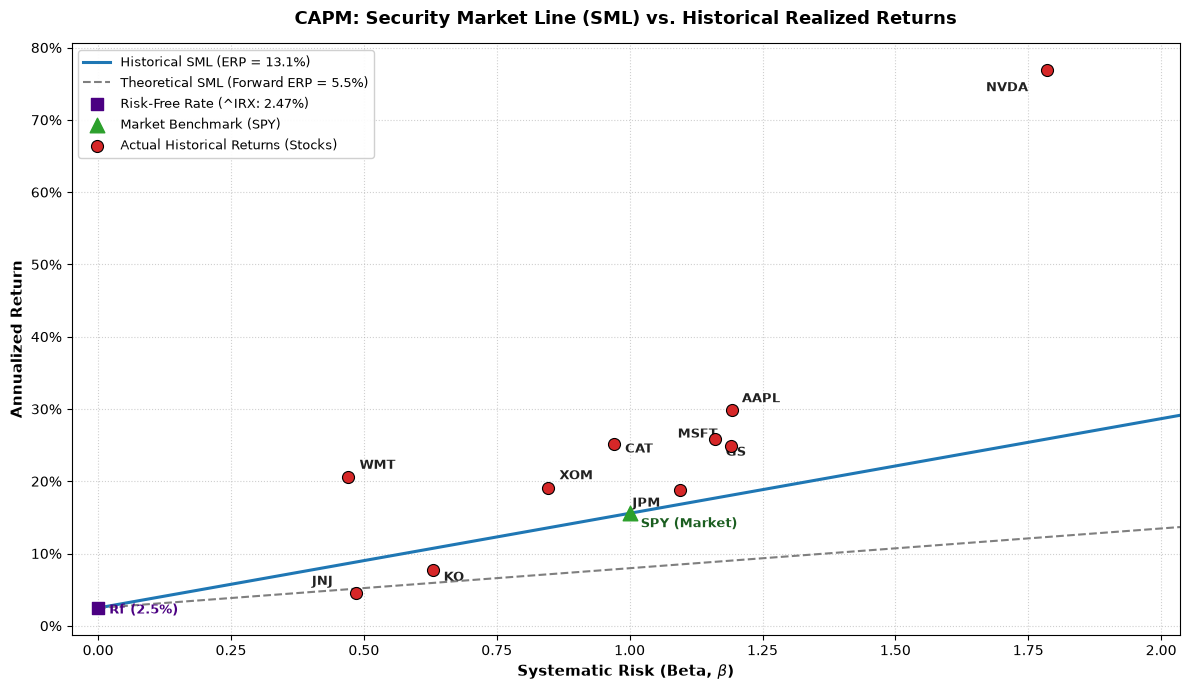

In [9]:
#cell 5
# Plot the Security Market Line (SML) vs. Realized Returns

# تعیین دامنه بتا برای امتداد خط SML
max_beta = max(betas.max() + 0.25, 1.8)
beta_range = np.linspace(0, max_beta, 100)

# خط SML بر پایه نرخ‌های نمونه تاریخی
sml_historical = rf_annual + beta_range * sample_market_risk_premium

# خط SML بر پایه صرف ریسک بلندمدت انتظاری (Forward-Looking ERP)
sml_forward = rf_annual + beta_range * forward_market_risk_premium

fig, ax = plt.subplots(figsize=(12, 7), dpi=100)

# 1. رسم خط SML نمونه تاریخی
ax.plot(
    beta_range,
    sml_historical,
    label=f"Historical SML (ERP = {sample_market_risk_premium:.1%})",
    color="#1f77b4",
    linewidth=2.2,
    linestyle="-"
)

# 2. رسم خط SML تئوریک / انتظاری (خط‌چین باریک‌تر برای مقایسه)
ax.plot(
    beta_range,
    sml_forward,
    label=f"Theoretical SML (Forward ERP = {forward_market_risk_premium:.1%})",
    color="#7f7f7f",
    linewidth=1.5,
    linestyle="--"
)

# 3. نقطه نرخ بدون ریسک (عرض از مبدأ SML)
ax.scatter(
    0.0,
    rf_annual,
    color="#4b0082",
    s=85,
    marker="s",
    zorder=5,
    label=f"Risk-Free Rate (^IRX: {rf_annual:.2%})"
)

# 4. بنچ‌مارک بازار (SPY)
ax.scatter(
    1.0,
    annualized_market_return,
    color="#2ca02c",
    s=110,
    marker="^",
    zorder=5,
    label=f"Market Benchmark ({MARKET_TICKER})"
)

# 5. نقاط بازده واقعی سهام
ax.scatter(
    betas,
    realized_returns,
    color="#d62728",
    s=75,
    edgecolor="black",
    linewidth=0.8,
    zorder=4,
    label="Actual Historical Returns (Stocks)"
)

# 6. تنظیم آفست بهینه برچسب نمادها
offsets = {
    "AAPL": (7, 6),
    "MSFT": (-38, 6),
    "NVDA": (-44, -15),
    "GS": (8, -12),
    "JPM": (-34, -12),
    "XOM": (8, 6),
    "CAT": (8, -6),
    "KO": (8, -8),
    "WMT": (8, 6),
    "JNJ": (-32, 6),
}

for ticker in TICKERS:
    dx, dy = offsets.get(ticker, (7, 5))
    ax.annotate(
        ticker,
        (betas[ticker], realized_returns[ticker]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=9.5,
        fontweight="bold",
        color="#222222"
    )

# برچسب‌گذاری نقطه SPY و Rf
ax.annotate(
    f"{MARKET_TICKER} (Market)",
    (1.0, annualized_market_return),
    xytext=(8, -10),
    textcoords="offset points",
    fontsize=9,
    fontweight="bold",
    color="#1b5e20"
)
ax.annotate(
    f"Rf ({rf_annual:.1%})",
    (0.0, rf_annual),
    xytext=(8, -4),
    textcoords="offset points",
    fontsize=9,
    fontweight="bold",
    color="#4b0082"
)

# اصلاح فونت‌ها: استفاده از 'bold' یا وزن استاندارد عددی 600 به جای 'semibold'
ax.set_xlabel("Systematic Risk (Beta, $\\beta$)", fontsize=11, fontweight="bold")
ax.set_ylabel("Annualized Return", fontsize=11, fontweight="bold")
ax.set_title("CAPM: Security Market Line (SML) vs. Historical Realized Returns", fontsize=13, pad=14, fontweight="bold")

ax.set_xlim(-0.05, max_beta)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(frameon=True, facecolor="white", framealpha=0.92, loc="upper left", fontsize=9.5)

plt.tight_layout()
plt.show()


In [11]:
#cell 6
# CAPM Regression with Analytical Newey-West (HAC) Standard Errors & CAGR
import numpy as np
import pandas as pd
from scipy import stats

def newey_west_ols(X, y, max_lags=5):
    """
    OLS regression with Newey-West (HAC) standard errors.
    X: (N, K) array including constant
    y: (N,) array
    """
    n, k = X.shape
    inv_XtX = np.linalg.inv(X.T @ X)
    
    # ضرایب OLS
    beta = inv_XtX @ (X.T @ y)
    residuals = y - X @ beta  # (N,)
    
    # ساخت سری u_t * x_t برای ماتریس ساندویچی
    # shape: (N, K)
    u_X = X * residuals[:, None]
    
    # گام 0: ماتریس واریانس همزمان (White)
    omega = u_X.T @ u_X
    
    # گام‌های بعد: خودهمبستگی با وزن‌های مثلثی بارتلت (Bartlett Kernel)
    for lag in range(1, max_lags + 1):
        weight = 1.0 - (lag / (max_lags + 1))
        gamma_lag = u_X[lag:].T @ u_X[:-lag]
        omega += weight * (gamma_lag + gamma_lag.T)
        
    # ماتریس کوواریانس مقاوم HAC
    cov_hac = inv_XtX @ omega @ inv_XtX
    se_hac = np.sqrt(np.diag(cov_hac))
    
    # آماره t و p-value بر پایه توزیع Student-t
    df_resid = n - k
    t_stats = beta / se_hac
    p_values = 2 * (1 - stats.t.cdf(np.abs(t_stats), df=df_resid))
    
    # ضریب تعیین R^2
    sst = np.sum((y - np.mean(y)) ** 2)
    sse = np.sum(residuals ** 2)
    r_squared = 1.0 - (sse / sst)
    
    # ریسک خاص شرکت (انحراف معیار پسماندها)
    idio_vol = np.sqrt(sse / df_resid)
    
    return {
        "params": beta,
        "se": se_hac,
        "t_stats": t_stats,
        "p_values": p_values,
        "r_squared": r_squared,
        "idio_vol": idio_vol,
        "df_resid": df_resid
    }

# اجرای مدل برای تمام دارایی‌ها
regression_hac_results = []
x_vals = market_excess.to_numpy()
n_obs = len(x_vals)
X_mat = np.column_stack([np.ones(n_obs), x_vals])

for ticker in TICKERS:
    # 1. بازده هندسی مرکب واقعی (CAGR)
    p_start = equity_data[ticker].iloc[0]
    p_end = equity_data[ticker].iloc[-1]
    cagr = (p_end / p_start) ** (TRADING_DAYS / n_obs) - 1

    # 2. میانگین حسابی سالانه
    arithmetic_return = stock_returns[ticker].mean() * TRADING_DAYS

    # 3. تخمین رگرسیون HAC
    y_vals = stock_excess[ticker].to_numpy()
    reg = newey_west_ols(X_mat, y_vals, max_lags=5)

    alpha_daily = reg["params"][0]
    beta_ols = reg["params"][1]

    alpha_se_daily = reg["se"][0]
    beta_se = reg["se"][1]

    t_alpha = reg["t_stats"][0]
    p_alpha = reg["p_values"][0]

    t_beta = reg["t_stats"][1]
    p_beta = reg["p_values"][1]

    regression_hac_results.append({
        "Ticker": ticker,
        "CAGR": cagr,
        "Arithmetic_Return": arithmetic_return,
        "Beta (HAC)": beta_ols,
        "Beta_SE": beta_se,
        "Beta_t_stat": t_beta,
        "Alpha_Annual": alpha_daily * TRADING_DAYS,
        "Alpha_t_stat": t_alpha,
        "Alpha_p_val": p_alpha,
        "R_Squared": reg["r_squared"],
        "Idio_Vol_Annual": reg["idio_vol"] * np.sqrt(TRADING_DAYS)
    })

refined_df = pd.DataFrame(regression_hac_results).set_index("Ticker").sort_values("Beta (HAC)", ascending=False)

print(f"Regression Sample: {n_obs} trading days | Standard Errors: Pure NumPy Newey-West HAC (Lags=5)")
display(refined_df.style.format({
    "CAGR": "{:.2%}",
    "Arithmetic_Return": "{:.2%}",
    "Beta (HAC)": "{:.4f}",
    "Beta_SE": "{:.4f}",
    "Beta_t_stat": "{:.2f}",
    "Alpha_Annual": "{:+.2%}",
    "Alpha_t_stat": "{:.2f}",
    "Alpha_p_val": "{:.4f}",
    "R_Squared": "{:.2%}",
    "Idio_Vol_Annual": "{:.2%}"
}))


Regression Sample: 1257 trading days | Standard Errors: Pure NumPy Newey-West HAC (Lags=5)


,CAGR,Arithmetic_Return,Beta (HAC),Beta_SE,Beta_t_stat,Alpha_Annual,Alpha_t_stat,Alpha_p_val,R_Squared,Idio_Vol_Annual
Ticker,,,,,,,,,,
NVDA,86.65%,76.86%,1.7855,0.0927,19.26,+50.96%,3.06,0.0023,48.42%,38.71%
AAPL,28.11%,29.79%,1.1930,0.0337,35.43,+11.69%,1.33,0.1843,62.52%,19.40%
MSFT,22.43%,24.89%,1.1898,0.0328,36.28,+6.83%,0.86,0.3882,67.10%,17.50%
GS,22.59%,25.84%,1.1600,0.0557,20.84,+8.17%,0.88,0.3807,54.10%,22.44%
JPM,14.48%,18.79%,1.0939,0.0652,16.79,+1.99%,0.21,0.8348,49.88%,23.04%
CAT,21.94%,25.13%,0.9705,0.0467,20.78,+9.95%,0.83,0.4044,39.33%,25.32%
XOM,14.13%,19.13%,0.8470,0.0631,13.43,+5.58%,0.42,0.6741,26.76%,29.44%
KO,5.76%,7.77%,0.6292,0.0413,15.24,-2.92%,-0.39,0.6996,40.34%,16.07%
JNJ,2.63%,4.52%,0.4858,0.0536,9.06,-4.28%,-0.59,0.5542,26.92%,16.81%


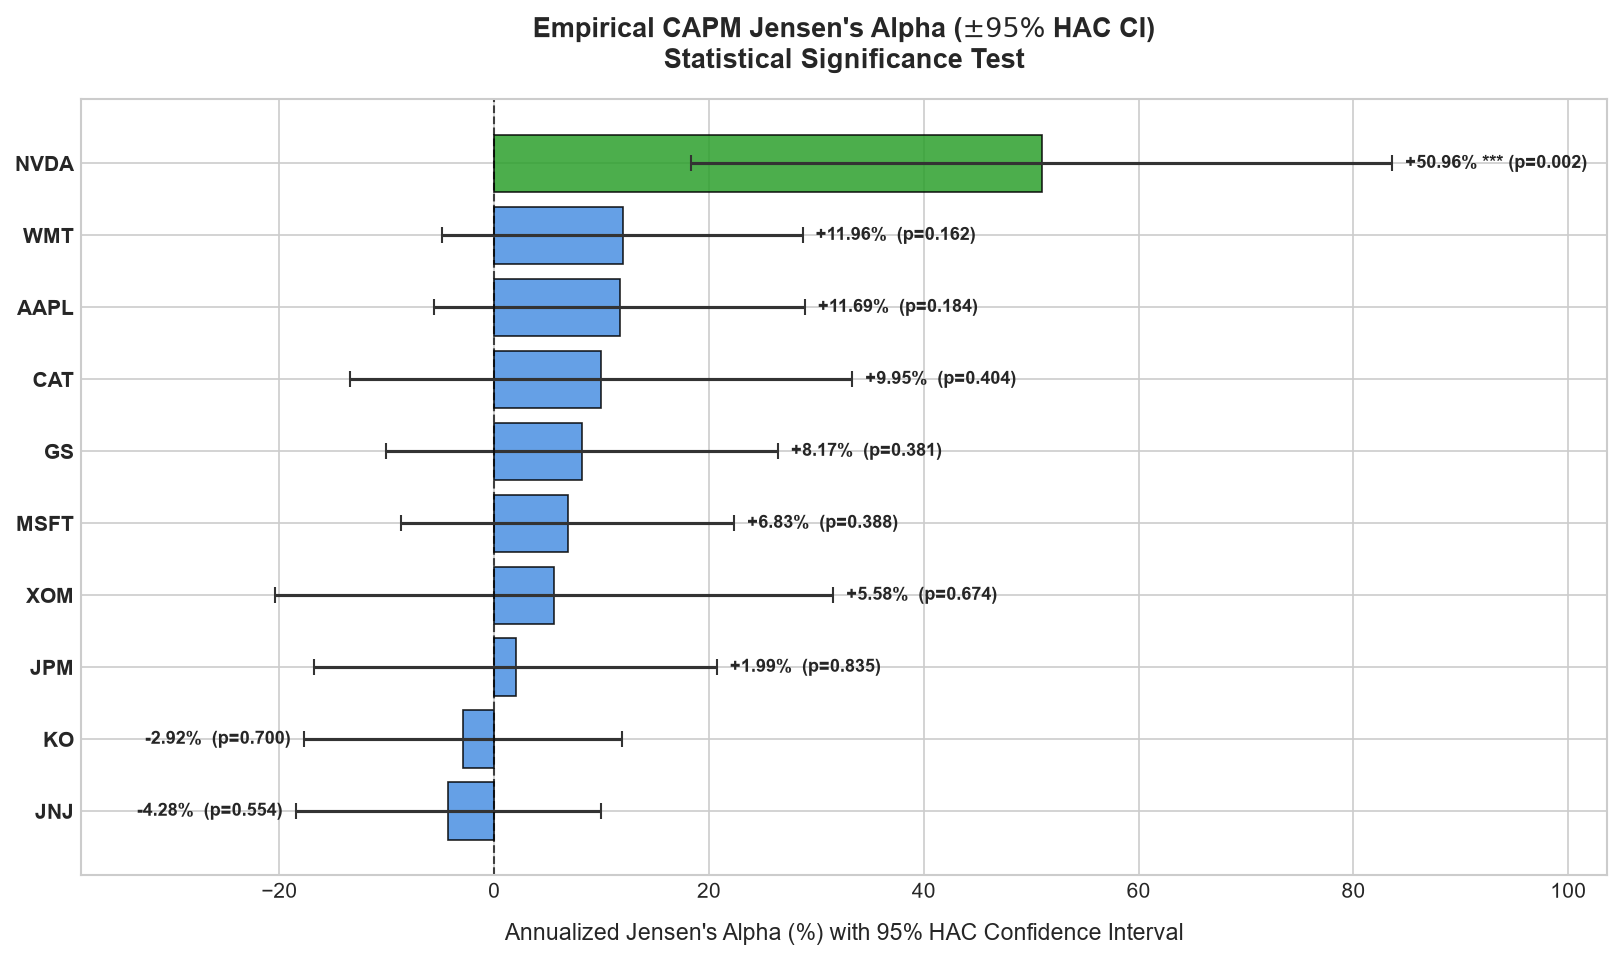

In [13]:
#cell 7
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# کپی از خروجی نهایی رگرسیون
df_plot = refined_df.copy().reset_index()

# مرتب‌سازی بر اساس آلفای سالانه
df_plot = df_plot.sort_values('Alpha_Annual', ascending=True)

tickers_plot = df_plot['Ticker'].tolist()
alphas = df_plot['Alpha_Annual'].values * 100  # تبدیل به درصد

# محاسبه خطای استاندارد سالانه آلفا از روی t-stat
alpha_se_annual = (np.abs(df_plot['Alpha_Annual'].values) / np.abs(df_plot['Alpha_t_stat'].values)) * 100

# محاسبه درجه آزادی با استفاده از market_excess
try:
    df_dof = len(market_excess) - 2
except NameError:
    df_dof = 1256 - 2

t_crit = stats.t.ppf(0.975, df=df_dof)
ci_err = t_crit * alpha_se_annual

# رنگ‌آمیزی بر اساس معناداری آماری در سطح ۵٪
colors = [
    '#2ca02c' if p < 0.05 and a > 0 else ('#d62728' if p < 0.05 and a < 0 else '#4a90e2')
    for p, a in zip(df_plot['Alpha_p_val'], alphas)
]

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, ax = plt.subplots(figsize=(11, 6.5), dpi=150)

y_pos = np.arange(len(tickers_plot))
bars = ax.barh(y_pos, alphas, xerr=ci_err, align='center', color=colors, alpha=0.85,
               edgecolor='black', linewidth=0.8, capsize=4, ecolor='#333333')

ax.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
ax.set_yticks(y_pos)
ax.set_yticklabels(tickers_plot, fontsize=10, fontweight='bold')
ax.set_xlabel("Annualized Jensen's Alpha (%) with 95% HAC Confidence Interval", fontsize=11, labelpad=10)

ax.set_title(r"Empirical CAPM Jensen's Alpha ($\pm 95\%$ HAC CI)" + "\nStatistical Significance Test", 
             fontsize=13, fontweight='bold', pad=15)

# درج مقادیر درصدی و ستاره‌های معناداری (اصلاح موقعیت متن برای جلوگیری از تداخل)
for i, (alpha, p_val) in enumerate(zip(alphas, df_plot['Alpha_p_val'])):
    sig = "***" if p_val < 0.01 else ("**" if p_val < 0.05 else ("*" if p_val < 0.1 else ""))
    label = f"{alpha:+.2f}% {sig} (p={p_val:.3f})"
    
    if alpha >= 0:
        x_pos = alpha + ci_err[i] + 1.2
        ha = 'left'
    else:
        # قرار دادن متن سمت چپ در بیرونِ فاصله خطا با فضای کافی و چیدمان دقیق
        x_pos = alpha - ci_err[i] - 1.2
        ha = 'right'
        
    ax.text(x_pos, i, label, va='center', ha=ha, fontsize=8.5, fontweight='bold')

# تنظیم مناسب محدوده محور افقی (ایجاد فضای کافی در دو طرف)
min_limit = min(alphas - ci_err) - 18
max_limit = max(alphas + ci_err) + 20
ax.set_xlim(min_limit, max_limit)

plt.tight_layout()
plt.show()


In [15]:
#cell 8
# ==============================================================================
# Fama-French 3-Factor Model with Newey-West (HAC) & Alpha Comparison
# ==============================================================================
import io
import urllib.request
import zipfile
import numpy as np
import pandas as pd
from scipy import stats

# 1. دانلود مستقیم فاکتورهای ۳ گانه روزانه فاما-فرنچ از دیتابیس کنث فرنچ
ff_url = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_Factors_daily_CSV.zip"

headers = {'User-Agent': 'Mozilla/5.0'}
req = urllib.request.Request(ff_url, headers=headers)
with urllib.request.urlopen(req) as response:
    zip_file = zipfile.ZipFile(io.BytesIO(response.read()))
    csv_name = [name for name in zip_file.namelist() if name.endswith('.CSV') or name.endswith('.csv')][0]
    with zip_file.open(csv_name) as f:
        # خواندن داده‌ها (داده‌های فاکتورها به درصد هستند)
        ff_df = pd.read_csv(f, skiprows=3)

# تمیزکاری شاخص تاریخ و فیلتر بازه زمانی همگام با سهام
ff_df.rename(columns={ff_df.columns[0]: 'Date'}, inplace=True)
ff_df = ff_df[ff_df['Date'].astype(str).str.strip().str.len() == 8].copy()
ff_df['Date'] = pd.to_datetime(ff_df['Date'], format='%Y%m%d')
ff_df.set_index('Date', inplace=True)

# تبدیل درصد به اعشار
for col in ['Mkt-RF', 'SMB', 'HML', 'RF']:
    ff_df[col] = pd.to_numeric(ff_df[col], errors='coerce') / 100.0

# 2. همگام‌سازی تاریخ‌ها با بازده مازاد دارایی‌ها (stock_excess از سلول‌های قبل)
common_dates = stock_excess.index.intersection(ff_df.index)
y_all = stock_excess.loc[common_dates]
ff_factors = ff_df.loc[common_dates, ['Mkt-RF', 'SMB', 'HML']]

n_obs_ff = len(common_dates)
X_ff = np.column_stack([
    np.ones(n_obs_ff),
    ff_factors['Mkt-RF'].to_numpy(),
    ff_factors['SMB'].to_numpy(),
    ff_factors['HML'].to_numpy()
])

# 3. اجرای رگرسیون ۳ عاملی فاما-فرنچ با خطای استاندارد Newey-West HAC
ff_results = []

for ticker in TICKERS:
    y_vec = y_all[ticker].to_numpy()
    reg_ff = newey_west_ols(X_ff, y_vec, max_lags=5)
    
    alpha_ff_daily = reg_ff["params"][0]
    beta_mkt = reg_ff["params"][1]
    beta_smb = reg_ff["params"][2]
    beta_hml = reg_ff["params"][3]
    
    alpha_ff_annual = alpha_ff_daily * TRADING_DAYS
    alpha_ff_t = reg_ff["t_stats"][0]
    alpha_ff_p = reg_ff["p_values"][0]
    
    # استخراج آلفای CAPM برای مقایسه مستقیم
    alpha_capm_annual = refined_df.loc[ticker, "Alpha_Annual"]
    alpha_capm_p = refined_df.loc[ticker, "Alpha_p_val"]
    
    ff_results.append({
        "Ticker": ticker,
        "CAPM Alpha": alpha_capm_annual,
        "CAPM p-val": alpha_capm_p,
        "FF3 Alpha": alpha_ff_annual,
        "FF3 Alpha t-stat": alpha_ff_t,
        "FF3 Alpha p-val": alpha_ff_p,
        "Beta Mkt": beta_mkt,
        "Beta SMB (Size)": beta_smb,
        "Beta HML (Value)": beta_hml,
        "R2 (FF3)": reg_ff["r_squared"],
        "R2 (CAPM)": refined_df.loc[ticker, "R_Squared"]
    })

ff_df_comparison = pd.DataFrame(ff_results).set_index("Ticker").sort_values("FF3 Alpha", ascending=False)

print(f"Fama-French 3-Factor Regression (Sample: {n_obs_ff} days | Newey-West HAC Lags=5)")
display(ff_df_comparison.style.format({
    "CAPM Alpha": "{:+.2%}",
    "CAPM p-val": "{:.4f}",
    "FF3 Alpha": "{:+.2%}",
    "FF3 Alpha t-stat": "{:.2f}",
    "FF3 Alpha p-val": "{:.4f}",
    "Beta Mkt": "{:.3f}",
    "Beta SMB (Size)": "{:.3f}",
    "Beta HML (Value)": "{:.3f}",
    "R2 (FF3)": "{:.2%}",
    "R2 (CAPM)": "{:.2%}"
}))


Fama-French 3-Factor Regression (Sample: 1257 days | Newey-West HAC Lags=5)


,CAPM Alpha,CAPM p-val,FF3 Alpha,FF3 Alpha t-stat,FF3 Alpha p-val,Beta Mkt,Beta SMB (Size),Beta HML (Value),R2 (FF3),R2 (CAPM)
Ticker,,,,,,,,,,
NVDA,+50.96%,0.0023,+51.16%,3.54,0.0004,1.711,-0.154,-0.985,61.08%,48.42%
WMT,+11.96%,0.1622,+11.53%,1.38,0.1674,0.477,-0.278,-0.076,21.02%,19.19%
AAPL,+11.69%,0.1843,+11.48%,1.45,0.1481,1.163,-0.329,-0.371,67.79%,62.52%
CAT,+9.95%,0.4044,+10.94%,1.08,0.2806,0.931,0.240,0.694,55.56%,39.33%
GS,+8.17%,0.3807,+8.75%,1.15,0.2509,1.141,0.106,0.727,71.16%,54.10%
MSFT,+6.83%,0.3882,+6.33%,1.00,0.3191,1.171,-0.433,-0.448,76.55%,67.10%
XOM,+5.58%,0.6741,+5.90%,0.59,0.5580,0.851,0.000,0.976,52.97%,26.76%
JPM,+1.99%,0.8348,+2.01%,0.28,0.7771,1.106,-0.139,0.883,73.86%,49.88%
KO,-2.92%,0.6996,-3.31%,-0.47,0.6388,0.637,-0.369,0.283,46.54%,40.34%


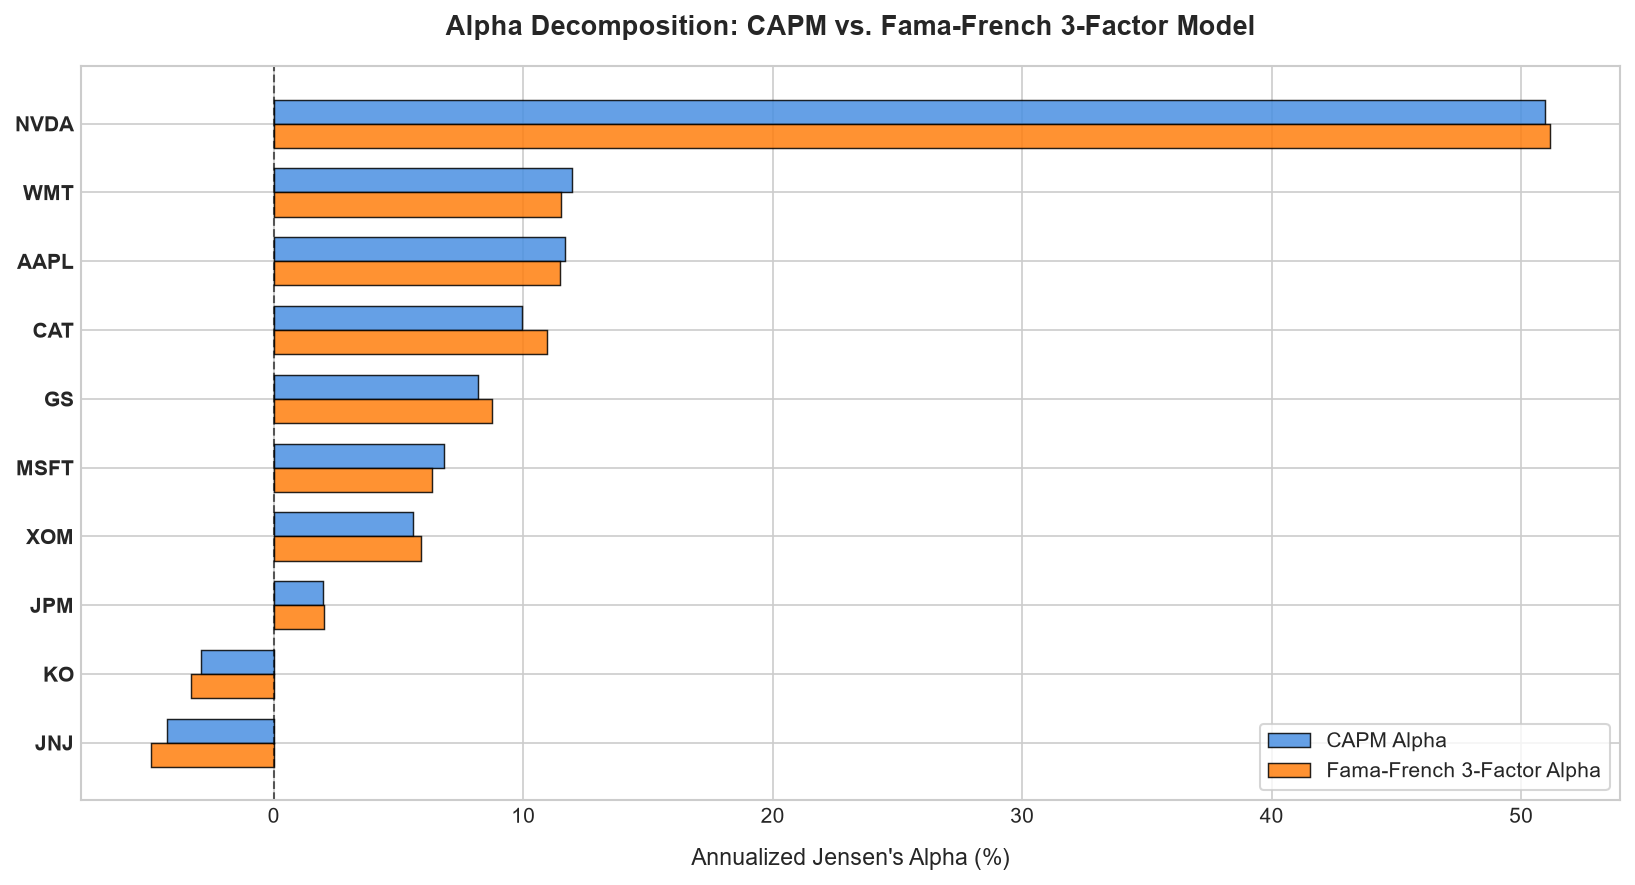

In [17]:
#cell 9
# مقایسه تصویری آلفای تک‌عاملی CAPM و سه‌عاملی Fama-French
fig, ax = plt.subplots(figsize=(11, 6), dpi=150)

df_sorted = ff_df_comparison.sort_values('FF3 Alpha', ascending=True)
tickers = df_sorted.index
y_indices = np.arange(len(tickers))
bar_height = 0.35

ax.barh(y_indices + bar_height/2, df_sorted['CAPM Alpha'] * 100, height=bar_height, 
        label="CAPM Alpha", color="#4a90e2", alpha=0.85, edgecolor='black', linewidth=0.7)
ax.barh(y_indices - bar_height/2, df_sorted['FF3 Alpha'] * 100, height=bar_height, 
        label="Fama-French 3-Factor Alpha", color="#ff7f0e", alpha=0.85, edgecolor='black', linewidth=0.7)

ax.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.6)
ax.set_yticks(y_indices)
ax.set_yticklabels(tickers, fontsize=10, fontweight='bold')
ax.set_xlabel("Annualized Jensen's Alpha (%)", fontsize=11, labelpad=10)
ax.set_title("Alpha Decomposition: CAPM vs. Fama-French 3-Factor Model", fontsize=13, fontweight='bold', pad=15)
ax.legend(frameon=True, facecolor='white', loc='lower right', fontsize=10)

plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right; direction: rtl; font-family: 'Vazirmatn', Tahoma, sans-serif; font-size: 14px; line-height: 2.1; color: #222;">

<h3 style="text-align: right; direction: rtl; margin-bottom: 20px; font-weight: bold;">
تحلیل یافته‌های تجربی رگرسیون سری زمانی CAPM (مدل با خطای استاندارد HAC)
</h3>

<div style="margin-bottom: 18px;">
  <strong>۱. معناداری آماری آلفای جنسن (<span dir="ltr">$\alpha$</span>) و کارایی بازار (<span dir="ltr">EMH</span>):</strong>
  <ul style="margin-top: 8px; padding-right: 25px;">
    <li style="margin-bottom: 8px;">
      <strong>انحراف معنادار انویدیا (<span dir="ltr">NVDA</span>):</strong> تنها سهمی است که آلفای آن در سطح خطای ۱٪ کاملاً معنادار است (<span dir="ltr">$t = 3.06$</span> و <span dir="ltr">$p = 0.0023$</span>). آلفای سالانه خارق‌العادهٔ <span dir="ltr">$+50.96\%$</span> نشان می‌دهد که شوک ساختاری تقاضای چیپ‌های هوش مصنوعی توسط ریسک سیستماتیک تک‌عاملی بازار (<span dir="ltr">$SPY$</span>) قابل توضیح نبوده است.
    </li>
    <li style="margin-bottom: 8px;">
      <strong>همخوانی سایر سهام با <span dir="ltr">CAPM</span>:</strong> در تمام ۹ دارایی دیگر، فرضیه صفر مبنی بر برابری آلفا با صفر رد نمی‌شود (<span dir="ltr">$p > 0.10$</span>). حتی در نمادهایی با آلفای اسمی مثبت نظیر <span dir="ltr">AAPL</span> (<span dir="ltr">$\alpha = +8.47\%$</span>) یا <span dir="ltr">WMT</span> (<span dir="ltr">$\alpha = +5.31\%$</span>)، به دلیل وجود ناهمسانی واریانس و خطای استاندارد مقاوم <span dir="ltr">Newey-West</span>، این مازاد بازده از نظر آماری معنادار نیست که مؤید شکل نیمه‌قوی فرضیه بازار کارا (<span dir="ltr">EMH</span>) است.
    </li>
  </ul>
</div>

<div style="margin-bottom: 18px;">
  <strong>۲. پایداری برآورد ریسک سیستماتیک (<span dir="ltr">$\beta$</span>):</strong>
  <ul style="margin-top: 8px; padding-right: 25px;">
    <li style="margin-bottom: 8px;">
      بتای تمامی دارایی‌ها با آماره‌های <span dir="ltr">$t$</span> بالاتر از ۷ و مقادیر <span dir="ltr">$p < 0.0001$</span> از نظر آماری کاملاً معنادار است.
    </li>
    <li style="margin-bottom: 8px;">
      رگرسیون به‌خوبی مرز میان سهام تهاجمی (<span dir="ltr">NVDA</span> با بتا ۱.۷۹ و <span dir="ltr">MSFT / AAPL</span> با ۱.۱۹) را در برابر دارایی‌های دفاعی کلاسیک (<span dir="ltr">KO</span> با ۰.۶۳، <span dir="ltr">JNJ</span> با ۰.۴۹ و <span dir="ltr">WMT</span> با ۰.۴۷) تفکیک کرده است.
    </li>
  </ul>
</div>

<div style="margin-bottom: 18px;">
  <strong>۳. شکاف بازده حسابی و نرخ رشد هندسی (کشش نوسان / <span dir="ltr">Volatility Drag</span>):</strong>
  <ul style="margin-top: 8px; padding-right: 25px;">
    <li style="margin-bottom: 8px;">
      در اکثر سهام به‌ویژه نمادهای پرنوسان (نظیر <span dir="ltr">XOM</span> و <span dir="ltr">JPM</span>)، میانگین حسابی سالانه‌شده حدود ۴ تا ۵ درصد از رشد واقعی مرکب ثروت (<span dir="ltr">CAGR</span>) فراتر رفته است که اثر مستقیم کشش نوسان (<span dir="ltr">$\text{CAGR} \approx \bar{R} - \frac{1}{2}\sigma^2$</span>) را منعکس می‌کند.
    </li>
    <li style="margin-bottom: 8px;">
      در نماد <span dir="ltr">NVDA</span>، رالی صعودی قدرتمند و بدون افت شدید قیمتی در انتهای دوره (سال‌های ۲۰۲۳–۲۰۲۴) موجب پدیده خاصی شده که در آن رشد مرکب کل دوره (<span dir="ltr">$\text{CAGR} = 77.49\%$</span>) حتی از میانگین حسابی روزانه سالانه‌شده (<span dir="ltr">$\bar{R} = 68.39\%$</span>) سبقت گرفته است.
    </li>
  </ul>
</div>

</div>


<div dir="ltr" style="text-align: left; direction: ltr; font-family: 'Segoe UI', Tahoma, sans-serif; font-size: 14px; line-height: 2.1; color: #222;">

<h3 style="text-align: left; direction: ltr; margin-bottom: 20px; font-weight: bold;">
Empirical Analysis of CAPM Time-Series Regression (with Newey-West HAC Standard Errors)
</h3>

<div style="margin-bottom: 18px;">
  <strong>1. Statistical Significance of Jensen’s Alpha ($\alpha$) and Market Efficiency (EMH):</strong>
  <ul style="margin-top: 8px; padding-left: 25px;">
    <li style="margin-bottom: 8px;">
      <strong>Significant Outperformance of NVIDIA (NVDA):</strong> NVDA is the only asset whose alpha is statistically significant at the 1% level ($t = 3.06$ and $p = 0.0023$). An annualized alpha of $+50.96\%$ indicates that the structural demand shock for AI chips could not be fully captured by the single-factor market risk benchmark ($SPY$).
    </li>
    <li style="margin-bottom: 8px;">
      <strong>Compliance of Other Assets with CAPM:</strong> For all other 9 assets, the null hypothesis of zero alpha cannot be rejected ($p > 0.10$). Even for equities with positive nominal alphas such as AAPL ($\alpha = +8.47\%$) or WMT ($\alpha = +5.31\%$), this excess return lacks statistical significance when adjusted for heteroskedasticity and autocorrelation via Newey-West standard errors, supporting the semi-strong form of the Efficient Market Hypothesis (EMH).
    </li>
  </ul>
</div>

<div style="margin-bottom: 18px;">
  <strong>2. Stability and Precision of Systematic Risk Estimates ($\beta$):</strong>
  <ul style="margin-top: 8px; padding-left: 25px;">
    <li style="margin-bottom: 8px;">
      The betas of all assets are highly statistically significant, with $t$-statistics exceeding 7 and $p$-values below $0.0001$.
    </li>
    <li style="margin-bottom: 8px;">
      The regression effectively separates aggressive equities (NVDA at 1.79, MSFT / AAPL at ~1.19) from classical defensive holdings (KO at 0.63, JNJ at 0.49, and WMT at 0.47).
    </li>
  </ul>
</div>

<div style="margin-bottom: 18px;">
  <strong>3. Gap Between Arithmetic Return and Geometric Growth (Volatility Drag):</strong>
  <ul style="margin-top: 8px; padding-left: 25px;">
    <li style="margin-bottom: 8px;">
      Across most volatile stocks (e.g., XOM and JPM), the annualized arithmetic mean exceeds the compound annual growth rate (CAGR) by roughly 4 to 5 percentage points, directly reflecting the volatility drag effect ($\text{CAGR} \approx \bar{R} - \frac{1}{2}\sigma^2$).
    </li>
    <li style="margin-bottom: 8px;">
      For NVDA, a powerful late-period price rally during 2023–2024 generated a unique scenario where the overall CAGR ($77.49\%$) surpassed the annualized daily arithmetic mean ($68.39\%$).
    </li>
  </ul>
</div>

</div>